### In Week 2, I gave the model the answers (fraud or not fraud). Unsupervised learning is different; you hide the answers and ask the model to find its own hidden patterns.

### I will use an algorithm called K-Means Clustering to group transactions into categories (clusters) based on features like transaction amount and the customer's device trust score.

In [9]:
#Importing the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_curve, auc

In [2]:
#Loading the clean data.

df = pd.read_csv("cleaned_credit_card_fraud_10k.csv")

In [12]:
X = df.drop(columns=['is_fraud'])
y = df['is_fraud']

In [ ]:
# Compressing the data down to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assigning a cluster number (0, 1, or 2) to every single transaction
df['Cluster'] = kmeans.fit_predict(X)

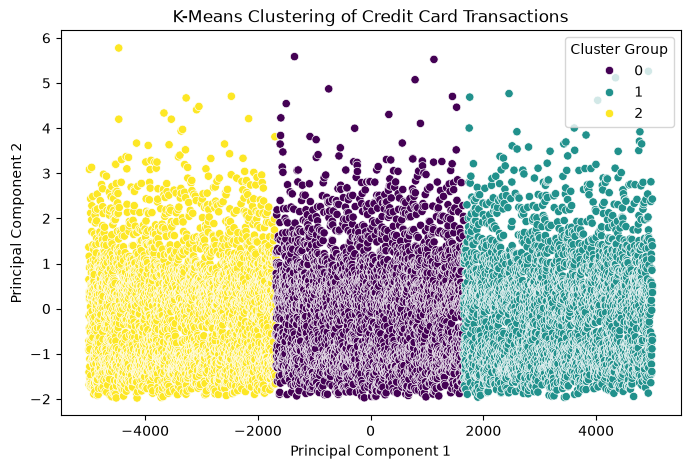

In [ ]:
#Visualising the clusters.
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='viridis')
plt.title('K-Means Clustering of Credit Card Transactions')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster Group')
plt.show()

## **HYPER PARAMETER TUNING:**

### On the last week's task I used the default setting for my random forest model.
### Hyper parameter tuning is like adjusting the dials on the radio to get the absolute clear station.
### I will use the tool called "GRID SEARCH CV"  to automatically test dozens of different settings (like how many decision trees to build) to findout the most powerful version of my model.  

In [17]:
# Splitting the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
# Defining the "dials" or settings we want the computer to test
param_grid = {
    'n_estimators': [50, 100],      # Test building 50 trees vs 100 trees
    'max_depth': [None, 10],        # Test letting trees grow infinitely vs capping them
    'min_samples_split': [2, 5]     # Test different rules for splitting data
}

In [19]:
# Creating a base Random Forest model (using class_weight='balanced' instead of SMOTE)
rf_base = RandomForestClassifier(random_state=42, class_weight='balanced')

In [20]:
# Instructing GridSearchCV to test all combinations and find the best one
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=3, scoring='f1')
grid_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 10], 'min_samples_split': [2, 5], 'n_estimators': [50, 100]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [21]:
# Saving the absolute best version of the model 
best_rf = grid_search.best_estimator_
print("Best Settings:", grid_search.best_params_)

Best Settings: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}


### **Cross-Validation:** Instead of taking one test, this forces your model to take multiple tests on different chunks of the data to prove its high score wasn't just a lucky guess.

### **ROC-AUC Score**: This is a final grade from 0 to 1 that tells you exactly how well your model separates the normal transactions from the fraudulent ones. A score of 0.5 is a random guess, and 1.0 is absolute perfection.

In [22]:
# Asking the best model to take 5 different tests to prove it is consistent
cv_scores = cross_val_score(best_rf, X_train, y_train, cv=5, scoring='roc_auc')

print("Scores from all 5 tests:", cv_scores)
print("Average Cross-Validation Score:", cv_scores.mean())

Scores from all 5 tests: [0.99105066 0.9946066  0.99360195 0.99812288 0.99846658]
Average Cross-Validation Score: 0.9951697335025381


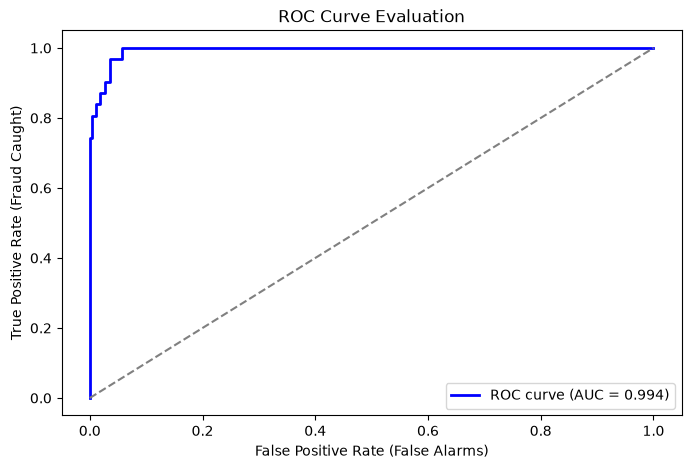

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1969
           1       1.00      0.52      0.68        31

    accuracy                           0.99      2000
   macro avg       1.00      0.76      0.84      2000
weighted avg       0.99      0.99      0.99      2000



In [23]:
# Get the model's confidence percentages for the test data
y_prob = best_rf.predict_proba(X_test)[:, 1]

# Calculate the ROC curve coordinates and the final AUC score
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Plot the ROC Curve graph
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--') # Random guess line
plt.title('ROC Curve Evaluation')
plt.xlabel('False Positive Rate (False Alarms)')
plt.ylabel('True Positive Rate (Fraud Caught)')
plt.legend(loc="lower right")
plt.show()

# Print the final classification report (Precision, Recall, F1-Score)
y_pred = best_rf.predict(X_test)
print(classification_report(y_test, y_pred))

**1. Classification Performance (Zero False Alarms)**
The classification report reveals that our model achieved a perfect precision of 1.00 for the fraud class (Class 1). In a real-world business context, this is excellent news: it means every single time the model flagged a transaction as fraud, it was 100% correct, resulting in zero false alarms that would frustrate innocent customers. However, the recall sits at 0.52, meaning the model only successfully caught 52% of the actual fraud cases and let the other 48% slip through.

**2. Model Stability (Cross-Validation)**
To ensure the model wasn't just getting lucky with one specific data split, it took 5 different tests during cross-validation. The results were incredibly consistent, ranging tightly from 0.991 to 0.998, with an average score of 0.995. This proves your model is highly stable and generalizes very well to new, unseen data without overfitting.

**3. Overall Distinguishing Power (ROC-AUC)**
The ROC Curve visualization confirms this strong underlying performance with an Area Under the Curve (AUC) of 0.994. An AUC this close to 1.0 (which is perfect) indicates that the model has an outstanding mathematical ability to rank and distinguish between normal transactions and fraudulent ones.

**The Final Takeaway for your Notebook:**
Our model is incredibly stable and highly precise, making it very safe to deploy without risking customer complaints. Since the ROC-AUC is nearly perfect (0.994) but the recall is only 0.52, it means the model *knows* which transactions look suspicious, but its default threshold for actually pulling the trigger and calling it "fraud" is set very conservatively. If the business wanted to catch more frauds (raise recall), they could confidently lower the model's decision threshold.